# Lusaka road crashes, 2016–2024

Dennis Kabaso is a computer science student in Lusaka, learning the work of a data analyst. This notebook is a first portfolio project in the style of a plain pandas analysis: load public tables, clean the labels, and answer one question at a time with a chart.

The tables are **Zambia Road Safety Data (2016–2024)** by Moses Mwale, Chuncky Kanchele, and Kelvin Mwangilwa (Zenodo, DOI [10.5281/zenodo.20022372](https://doi.org/10.5281/zenodo.20022372), CC BY 4.0). A row is a **total** for a year, a province, and a category. It is not one row per crash.

Unless a question says otherwise, the place is **Lusaka Province**. The files spell that name `Lusaka` or `LUSAKA`. After cleaning, the filter is `province == "LUSAKA"`. KKIA, the airport reporting division, stays separate. It is not added into Lusaka.


## Questions

1. How many crashes did Lusaka record from 2016 to 2024, and how serious were they?
2. Which quarter is busiest, and how do urban and rural crashes compare?
3. What are the top 10 reported causes, and which of them changed the most?
4. Which days and time slots have the most crashes?
5. Who is killed most often, which vehicles are involved, and how does Lusaka compare with other provinces?
6. Optional: how many crashes does Zambia record per 100,000 people?


## Setup

The charts in this notebook are also written to `images/`, so the same pictures can sit in the README.


In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import FuncFormatter, MaxNLocator

# Muted colours that stay distinct in a stacked bar and in print.
BLUE = "#4C78A8"
TEAL = "#72B7B2"
ORANGE = "#F58518"
RED = "#E45756"
GOLD = "#E6C35C"

SEVERITY_ORDER = ["Damage only", "Slight", "Serious", "Fatal"]
SEVERITY_COLORS = {
    "Damage only": BLUE,
    "Slight": GOLD,
    "Serious": ORANGE,
    "Fatal": RED,
}
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
QUARTER_ORDER = ["Q1", "Q2", "Q3", "Q4"]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"


def find_root():
    """Find the project folder whether Jupyter starts in the repo or in notebooks/."""
    start = Path.cwd().resolve()
    for candidate in [start, *start.parents]:
        marker = candidate / "data" / "raw" / "x1_annual_rta_reported.csv"
        if marker.exists():
            return candidate
    raise FileNotFoundError("Could not find data/raw. Run this notebook from the project folder.")


def thousands(ax, axis="y"):
    """Show 12000 as 12,000 on one axis."""
    formatter = FuncFormatter(lambda value, _pos: f"{int(value):,}")
    target = ax.yaxis if axis == "y" else ax.xaxis
    target.set_major_formatter(formatter)


def label_vertical(ax):
    """Write the count just above each simple bar."""
    for bar in ax.patches:
        height = bar.get_height()
        ax.annotate(
            f"{int(height):,}",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points",
        )
    top = max(bar.get_height() for bar in ax.patches)
    ax.set_ylim(0, top * 1.16)


def label_horizontal(ax):
    """Write the count just to the right of each horizontal bar."""
    for bar in ax.patches:
        width = bar.get_width()
        ax.annotate(
            f"{int(width):,}",
            (width, bar.get_y() + bar.get_height() / 2),
            ha="left",
            va="center",
            fontsize=8,
            xytext=(4, 0),
            textcoords="offset points",
        )
    right = max(bar.get_width() for bar in ax.patches)
    ax.set_xlim(0, right * 1.18)


def save_fig(fig, filename):
    """Save a chart under images/ and keep it visible in the notebook."""
    path = IMAGES / filename
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    display(fig)
    plt.close(fig)
    print(f"Saved images/{filename}")


ROOT = find_root()
DATA = ROOT / "data" / "raw"
IMAGES = ROOT / "images"
OUTPUTS = ROOT / "outputs"
IMAGES.mkdir(exist_ok=True)
OUTPUTS.mkdir(exist_ok=True)

# Sentences printed at the end. The README quotes this run, not hand-typed totals.
findings = []
print(f"Project folder: {ROOT}")


Project folder: /workspace


## Load the tables

Seven tables answer the questions. `published_derived_indicators.csv` is not a crash table. It is the small population series the dataset authors published, and it is used only in the last section.

| File | What a row counts |
| --- | --- |
| `x1_annual_rta_reported.csv` | Crashes in a year, by province and severity |
| `x2_total_no_rt_cs_by_quarter.csv` | Crashes in a quarter, by province and urban/rural |
| `x10_causes_of_accidents.csv` | Crashes given a reported cause |
| `x11_day_of_accidents.csv` | Crashes by day of the week |
| `x12_times_of_accidents.csv` | Crashes by time slot. The column is named `day`, but the values are times |
| `x6_class_of_persons_kille.csv` | People killed, by road-user class |
| `x9_types_of_motor_vehicles.csv` | Vehicles involved, by type |


In [2]:
files = {
    "x1": "x1_annual_rta_reported.csv",
    "x2": "x2_total_no_rt_cs_by_quarter.csv",
    "x6": "x6_class_of_persons_kille.csv",
    "x9": "x9_types_of_motor_vehicles.csv",
    "x10": "x10_causes_of_accidents.csv",
    "x11": "x11_day_of_accidents.csv",
    "x12": "x12_times_of_accidents.csv",
}

raw = {name: pd.read_csv(DATA / filename) for name, filename in files.items()}

for name, df in raw.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

print()
print("Severity labels in x1:", sorted(raw["x1"]["accident_type"].astype(str).unique()))
print("A sample of province labels in x6:", sorted(raw["x6"]["division"].astype(str).unique())[:8], "...")
print("x12 column named 'day' holds time slots:", raw["x12"]["day"].unique().tolist())
display(raw["x1"].head(3))


x1: 372 rows, 7 columns
x2: 664 rows, 8 columns
x6: 581 rows, 7 columns
x9: 913 rows, 9 columns
x10: 4,067 rows, 9 columns
x11: 581 rows, 9 columns
x12: 664 rows, 9 columns

Severity labels in x1: ['DAMAGE ONLY', 'FATAL', 'SERIOUS', 'SLIGHT', 'fatal', 'serious', 'slight']
A sample of province labels in x6: ['C/BELT', 'C/Belt', 'CENTRAL', 'Central', 'Copperbelt', 'EASTERN', 'Eastern', 'KKIA'] ...
x12 column named 'day' holds time slots: ['0700-0900 Hrs', '0900-1200 hrs', '1200-1430 hrs', '1430-1600 hrs', '1600-1800 hrs', '1800-2000 hrs', '2000-2359 hrs', '2359-0700 hrs']


,index,tab_no,table,year,province,accident_type,count
0,1,1,ANNUAL ROAD TRAFFIC ACCIDENTS REPORTED FROM 1S...,2019,LUSAKA,FATAL,383
1,2,1,ANNUAL ROAD TRAFFIC ACCIDENTS REPORTED FROM 1S...,2019,C/BELT,FATAL,231
2,3,1,ANNUAL ROAD TRAFFIC ACCIDENTS REPORTED FROM 1S...,2019,CENTRAL,FATAL,216


### Clean up the data

Three things get in the way of a straight `groupby`.

- Some files carry empty Excel pivot columns (`x9`, `x10`, `x11` on the cause, day, time, and vehicle tables). Those cells are blank. They are not missing crash counts.
- The same province is written several ways (`Lusaka`, `LUSAKA`, `C/BELT`, `Copperbelt`, `N/ WESTERN`). Severity is `FATAL` in some years and `fatal` in others.
- A few cause labels change spelling from one year to the next (`Stationery` / `Stationary`, `repare` / `repair`). If we leave them split, one cause is counted as two.

Zeros are kept. A zero means the report recorded none, not that the cell was blank. Nothing is imputed.


In [3]:
JUNK_COLUMNS = {"x9", "x10", "x11"}
ID_COLUMNS = ["index", "tab_no", "table_no", "table", "table_name"]

# Same place, different spellings. KKIA stays KKIA: it is the airport division, not a province.
PROVINCE_MAP = {
    "LUSAKA": "LUSAKA",
    "C/BELT": "COPPERBELT",
    "COPPERBELT": "COPPERBELT",
    "CENTRAL": "CENTRAL",
    "SOUTHERN": "SOUTHERN",
    "EASTERN": "EASTERN",
    "NORTHERN": "NORTHERN",
    "LUAPULA": "LUAPULA",
    "N/WESTERN": "NORTH-WESTERN",
    "N/ WESTERN": "NORTH-WESTERN",
    "WESTERN": "WESTERN",
    "MUCHINGA": "MUCHINGA",
    "KKIA": "KKIA",
}
SEVERITY_MAP = {
    "FATAL": "Fatal",
    "SERIOUS": "Serious",
    "SLIGHT": "Slight",
    "DAMAGE ONLY": "Damage only",
}
# Spelling variants of one cause. The canonical label is the corrected wording.
CAUSE_FIXES = {
    "C22. Pedalcyclist holding onto another vehicle": "C22. Pedalcyclist holding on to another vehicle",
    "D24. Walking,standing on road": "D24. Walking, standing on road",
    "E29. Negligency on the part of the conductor": "E29. Negligence on the part of the conductor",
    "G33. Stationery vehicle dangerously placed": "G33. Stationary vehicle dangerously placed",
    "G34. Other obstractions": "G34. Other obstructions",
    "I44. Road surface in need of repare": "I44. Road surface in need of repair",
}
TIME_LABELS = {
    "0700-0900 Hrs": "07:00–09:00",
    "0900-1200 hrs": "09:00–12:00",
    "1200-1430 hrs": "12:00–14:30",
    "1430-1600 hrs": "14:30–16:00",
    "1600-1800 hrs": "16:00–18:00",
    "1800-2000 hrs": "18:00–20:00",
    "2000-2359 hrs": "20:00–23:59",
    "2359-0700 hrs": "23:59–07:00",
}
TIME_ORDER = list(TIME_LABELS.values())


def missing_cell_percent(df):
    """Share of cells that are blank, as a percent."""
    return float(df.isna().to_numpy().mean() * 100)


def drop_junk_columns(df):
    """Drop unnamed columns and the empty Excel pivot columns."""
    keep = []
    for column in df.columns:
        name = str(column).strip()
        if name.startswith("Unnamed") or name.lower() in JUNK_COLUMNS:
            continue
        keep.append(column)
    return df.loc[:, keep].copy()


def drop_id_columns(df):
    """Drop the repeated table-name and row-index columns when a file has them."""
    present = [column for column in ID_COLUMNS if column in df.columns]
    return df.drop(columns=present)


def standardise_province(series):
    """Trim, upper-case, and map known name variants onto one label."""
    cleaned = series.astype(str).str.strip().str.replace(r"\s+", " ", regex=True).str.upper()
    mapped = cleaned.map(PROVINCE_MAP)
    unknown = sorted(cleaned[mapped.isna()].unique())
    if unknown:
        raise ValueError(f"Unmapped province names: {unknown}")
    return mapped


def standardise_severity(series):
    """Map FATAL/fatal and the other severity labels onto one set of names."""
    cleaned = series.astype(str).str.strip().str.upper()
    mapped = cleaned.map(SEVERITY_MAP)
    unknown = sorted(cleaned[mapped.isna()].unique())
    if unknown:
        raise ValueError(f"Unmapped severity labels: {unknown}")
    return mapped


def standardise_cause(series):
    """Collapse extra spaces, then merge cause labels that differ only by a typo."""
    cleaned = series.astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    return cleaned.replace(CAUSE_FIXES)


def standardise_time_slot(series):
    """Rename the mislabelled time-slot values to 24-hour ranges."""
    cleaned = series.astype(str).str.strip()
    mapped = cleaned.map(TIME_LABELS)
    unknown = sorted(cleaned[mapped.isna()].unique())
    if unknown:
        raise ValueError(f"Unmapped time slots: {unknown}")
    return mapped


def short_cause(label):
    """Drop a prefix such as 'A17. ' so a chart label is readable."""
    text = re.sub(r"^[A-Z]\d+\.\s*", "", str(label)).strip()
    if not text:
        return str(label)
    return text[0].upper() + text[1:]


before = {name: missing_cell_percent(df) for name, df in raw.items()}
dropped = {}
cleaned_raw = {}
for name, df in raw.items():
    kept = drop_junk_columns(df)
    dropped[name] = [column for column in df.columns if column not in kept.columns]
    cleaned_raw[name] = kept

after = {name: missing_cell_percent(df) for name, df in cleaned_raw.items()}
missing_report = pd.DataFrame({"blank_cells_before_pct": before, "blank_cells_after_pct": after}).round(2)
print("Columns removed as pivot leftovers:")
for name, columns in dropped.items():
    print(f"  {name}: {columns if columns else 'none'}")
display(missing_report)


Columns removed as pivot leftovers:
  x1: none
  x2: none
  x6: none
  x9: ['x10', 'x11']
  x10: ['x9', 'x10']
  x11: ['x9', 'x10']
  x12: ['x9', 'x10']


,blank_cells_before_pct,blank_cells_after_pct
x1,0.00,0.0
x2,0.00,0.0
x6,0.00,0.0
x9,21.98,0.0
x10,22.16,0.0
x11,21.84,0.0
x12,21.89,0.0


The blank cells were the pivot leftovers. For example, table x9 stores a real vehicle count in `count`, and beside it a year-total that was pasted in from a spreadsheet pivot. The count stays. The pasted column goes.

On x10, about 22% of cells are blank before that drop, which matches the dataset's own data-quality note. After the drop, the analysis columns are complete.


In [4]:
# x1: one row per year, province, and severity.
annual = drop_id_columns(cleaned_raw["x1"])
annual["year"] = pd.to_numeric(annual["year"], errors="coerce")
annual["count"] = pd.to_numeric(annual["count"], errors="coerce")
annual["province"] = standardise_province(annual["province"])
annual["severity"] = standardise_severity(annual["accident_type"])
annual = annual.drop(columns=["accident_type"])

# x2: quarter and urban/rural. There is no 2016 in this file.
quarterly = drop_id_columns(cleaned_raw["x2"])
quarterly["year"] = pd.to_numeric(quarterly["year"], errors="coerce")
quarterly["accidents"] = pd.to_numeric(quarterly["accidents"], errors="coerce")
quarterly["province"] = standardise_province(quarterly["province"])
quarterly["quarter"] = quarterly["quarter"].astype(str).str.strip().str.upper()
quarterly["location"] = quarterly["location"].astype(str).str.strip().str.title()

# x10: reported cause. Merge the spelling variants before any ranking.
causes = drop_id_columns(cleaned_raw["x10"])
causes["year"] = pd.to_numeric(causes["year"], errors="coerce")
causes["count"] = pd.to_numeric(causes["count"], errors="coerce")
causes["province"] = standardise_province(causes["province"])
original_causes = causes["cause"].copy()
causes["cause"] = standardise_cause(causes["cause"])

# x11: day of week.
days = drop_id_columns(cleaned_raw["x11"])
days["year"] = pd.to_numeric(days["year"], errors="coerce")
days["accidents"] = pd.to_numeric(days["accidents"], errors="coerce")
days["province"] = standardise_province(days["province"])
days["day"] = days["day"].astype(str).str.strip().str.title()

# x12: the column is called day, but every value is a time slot.
times = drop_id_columns(cleaned_raw["x12"])
times["year"] = pd.to_numeric(times["year"], errors="coerce")
times["accidents"] = pd.to_numeric(times["accidents"], errors="coerce")
times["province"] = standardise_province(times["province"])
times = times.rename(columns={"day": "time_slot"})
times["time_slot"] = standardise_time_slot(times["time_slot"])

# x6: people killed. The province column is named division in this file.
killed = drop_id_columns(cleaned_raw["x6"])
killed["year"] = pd.to_numeric(killed["year"], errors="coerce")
killed["number"] = pd.to_numeric(killed["number"], errors="coerce")
killed = killed.rename(columns={"division": "province"})
killed["province"] = standardise_province(killed["province"])
killed["casualty_type"] = killed["casualty_type"].astype(str).str.strip()

# x9: vehicles involved in crashes, which is not the same thing as a crash count.
vehicles = drop_id_columns(cleaned_raw["x9"])
vehicles["year"] = pd.to_numeric(vehicles["year"], errors="coerce")
vehicles["count"] = pd.to_numeric(vehicles["count"], errors="coerce")
vehicles["province"] = standardise_province(vehicles["province"])
vehicles["vehicle_type"] = vehicles["vehicle_type"].astype(str).str.strip()

measure_missing = {
    "annual crashes": int(annual["count"].isna().sum()),
    "quarterly crashes": int(quarterly["accidents"].isna().sum()),
    "causes": int(causes["count"].isna().sum()),
    "days": int(days["accidents"].isna().sum()),
    "time slots": int(times["accidents"].isna().sum()),
    "people killed": int(killed["number"].isna().sum()),
    "vehicles": int(vehicles["count"].isna().sum()),
}
print("Missing values left in the count columns:", measure_missing)
print(f"Cause labels: {original_causes.nunique()} spellings in the file, {causes['cause'].nunique()} after the fixes.")

changed = pd.DataFrame({"original": original_causes, "cleaned": causes["cause"]})
changed = changed.loc[changed["original"] != changed["cleaned"]].drop_duplicates().sort_values("cleaned")
display(changed)

if set(quarterly["location"].unique()) != {"Urban", "Rural"}:
    raise ValueError(f"Unexpected location labels: {quarterly['location'].unique()}")
if set(days["day"].unique()) - set(DAY_ORDER):
    raise ValueError(f"Unexpected day labels: {set(days['day'].unique()) - set(DAY_ORDER)}")


Missing values left in the count columns: {'annual crashes': 0, 'quarterly crashes': 0, 'causes': 0, 'days': 0, 'time slots': 0, 'people killed': 0, 'vehicles': 0}
Cause labels: 56 spellings in the file, 49 after the fixes.


,original,cleaned
21,C22. Pedalcyclist holding onto another vehicle,C22. Pedalcyclist holding on to another vehicle
2081,"D24. Walking,standing on road","D24. Walking, standing on road"
2083,D26. Sudden illness,D26. Sudden illness
518,E29. Negligency on the part of the conductor,E29. Negligence on the part of the conductor
522,G33. Stationery vehicle dangerously placed,G33. Stationary vehicle dangerously placed
523,G34. Other obstractions,G34. Other obstructions
533,I44. Road surface in need of repare,I44. Road surface in need of repair


### Checks before the questions

Lusaka's quarterly totals should match Lusaka's annual totals in the years both tables cover. Where they do, the quarter and urban/rural answers are the same crashes as the severity table, just split a different way. A mismatch is reported, not patched.


In [5]:
def assert_unique(df, keys, label):
    """Stop if cleaning collapsed two different rows onto the same key."""
    duplicates = int(df.duplicated(keys).sum())
    if duplicates:
        raise ValueError(f"{label} has {duplicates} duplicate rows for {keys}")


assert_unique(annual, ["year", "province", "severity"], "annual")
assert_unique(quarterly, ["year", "quarter", "province", "location"], "quarterly")
assert_unique(causes, ["year", "province", "cause"], "causes")
assert_unique(days, ["year", "province", "day"], "days")
assert_unique(times, ["year", "province", "time_slot"], "times")
assert_unique(killed, ["year", "province", "casualty_type"], "people killed")
assert_unique(vehicles, ["year", "province", "vehicle_type"], "vehicles")

annual_totals = annual.groupby(["year", "province"])["count"].sum().rename("annual")
quarter_totals = quarterly.groupby(["year", "province"])["accidents"].sum().rename("quarterly")
compared = pd.concat([annual_totals, quarter_totals], axis=1).dropna()
compared["gap"] = compared["quarterly"] - compared["annual"]
mismatches = compared.loc[compared["gap"] != 0].sort_values("gap")

lusaka_match = compared.loc[compared.index.get_level_values("province") == "LUSAKA", "gap"]
if not (lusaka_match == 0).all():
    raise ValueError("Lusaka annual and quarterly totals disagree; the quarter charts would mix two definitions.")

print("Lusaka annual totals match the quarterly totals in every shared year.")
print("Province-years where the quarterly table does not match the annual table:")
display(mismatches if len(mismatches) else "None")
print("Years in x1:", [int(year) for year in sorted(annual["year"].unique())])
print("Years in x2, x6, x9, x10, x11, x12:", [int(year) for year in sorted(quarterly["year"].unique())])
print("KKIA years in x1:", [int(year) for year in sorted(annual.loc[annual["province"] == "KKIA", "year"].unique())])
print(f"Cause rows stored as zero: {(causes['count'] == 0).mean() * 100:.1f}% (kept as recorded zeros).")


Lusaka annual totals match the quarterly totals in every shared year.
Province-years where the quarterly table does not match the annual table:


,,annual,quarterly,gap
year,province,,,
2018,EASTERN,1472,1671.0,199.0


Years in x1: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
Years in x2, x6, x9, x10, x11, x12: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
KKIA years in x1: [2018, 2019, 2020]
Cause rows stored as zero: 24.6% (kept as recorded zeros).


## Question 1. How many crashes did Lusaka record, and how serious were they?

Table x1 covers 2016–2024. Severity has four levels: fatal, serious, slight, and damage only (a reported crash with no injury). Damage-only crashes dominate the count, so a chart of all crashes and a chart of the injury crashes are shown side by side. The injury chart would be a thin strip on top of the damage-only bars.


In [6]:
lusaka_annual = annual.loc[annual["province"] == "LUSAKA"].copy()
by_year = (
    lusaka_annual.groupby(["year", "severity"])["count"]
    .sum()
    .unstack("severity")
    .reindex(columns=SEVERITY_ORDER)
    .fillna(0)
    .sort_index()
    .astype(int)
)
by_year["Total"] = by_year.sum(axis=1)
display(by_year)

totals = by_year["Total"]
severity_totals = by_year[SEVERITY_ORDER].sum()
grand = int(severity_totals.sum())
national_total = int(annual["count"].sum())
national_fatal = int(annual.loc[annual["severity"] == "Fatal", "count"].sum())
lusaka_fatal = int(severity_totals["Fatal"])

peak_year = int(totals.idxmax())
low_year = int(totals.idxmin())
fatal_peak_year = int(by_year["Fatal"].idxmax())

print(f"Lusaka Province recorded {grand:,} crashes from 2016 to 2024.")
for severity in SEVERITY_ORDER:
    count = int(severity_totals[severity])
    print(f"  {severity}: {count:,} ({count / grand * 100:.1f}%)")
print(
    f"Busiest year: {peak_year} ({int(totals.max()):,} crashes). "
    f"Quietest year: {low_year} ({int(totals.min()):,})."
)
print(
    f"Fatal crashes peaked in {fatal_peak_year} "
    f"({int(by_year.loc[fatal_peak_year, 'Fatal']):,}), not in the busiest year overall."
)
print(
    f"Lusaka is {grand / national_total * 100:.1f}% of national crashes "
    f"({grand:,} of {national_total:,}) but {lusaka_fatal / national_fatal * 100:.1f}% of fatal crashes "
    f"({lusaka_fatal:,} of {national_fatal:,})."
)

findings.append(
    f"From 2016 to 2024, Lusaka Province recorded {grand:,} reported crashes. "
    f"{int(severity_totals['Damage only']):,} ({severity_totals['Damage only'] / grand * 100:.1f}%) were damage only, "
    f"{int(severity_totals['Slight']):,} ({severity_totals['Slight'] / grand * 100:.1f}%) slight, "
    f"{int(severity_totals['Serious']):,} ({severity_totals['Serious'] / grand * 100:.1f}%) serious, and "
    f"{lusaka_fatal:,} ({lusaka_fatal / grand * 100:.1f}%) fatal."
)
findings.append(
    f"The busiest year was {peak_year} with {int(totals.max()):,} crashes, and the quietest was {low_year} "
    f"with {int(totals.min()):,}. Fatal crashes peaked in {fatal_peak_year} "
    f"({int(by_year.loc[fatal_peak_year, 'Fatal']):,}), which is not the year with the most crashes."
)
findings.append(
    f"Lusaka accounted for {grand / national_total * 100:.1f}% of crashes reported in Zambia "
    f"({grand:,} of {national_total:,}) but {lusaka_fatal / national_fatal * 100:.1f}% of fatal crashes "
    f"({lusaka_fatal:,} of {national_fatal:,}). The extra volume is mostly damage-only crashes."
)


severity,Damage only,Slight,Serious,Fatal,Total
year,,,,,
2016,13459,2556,850,452,17317
2017,12143,2598,818,418,15977
2018,12339,2671,777,389,16176
2019,12635,2620,797,383,16435
2020,11856,2744,732,408,15740
2021,13570,2924,792,488,17774
2022,14202,2927,792,472,18393
2023,16243,3471,850,406,20970
2024,14344,3571,859,406,19180


Lusaka Province recorded 157,962 crashes from 2016 to 2024.
  Damage only: 120,791 (76.5%)
  Slight: 26,082 (16.5%)
  Serious: 7,267 (4.6%)
  Fatal: 3,822 (2.4%)
Busiest year: 2023 (20,970 crashes). Quietest year: 2020 (15,740).
Fatal crashes peaked in 2021 (488), not in the busiest year overall.
Lusaka is 54.3% of national crashes (157,962 of 290,837) but 25.9% of fatal crashes (3,822 of 14,743).


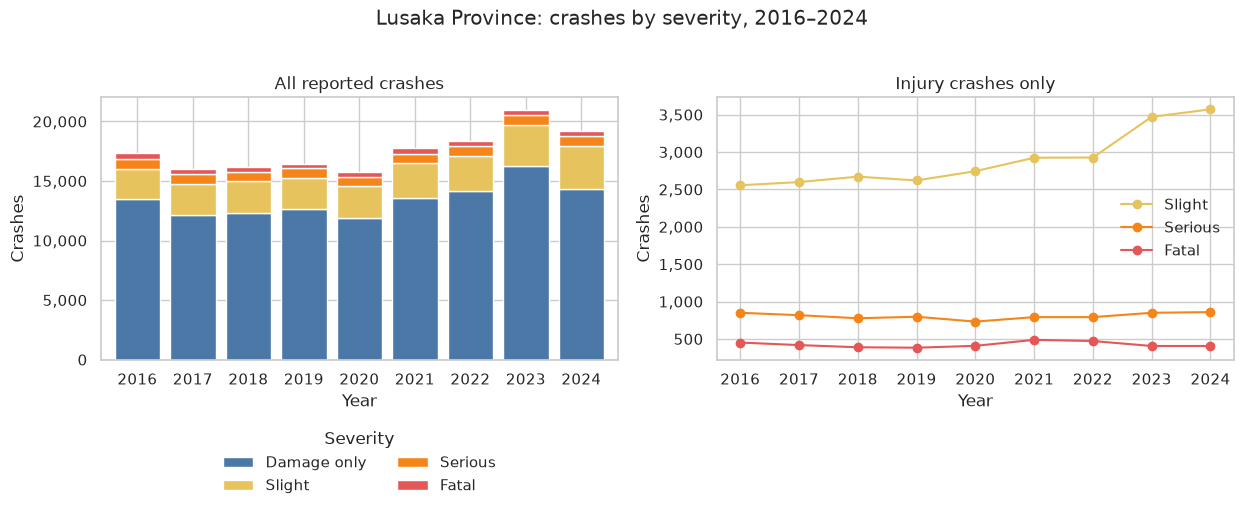

Saved images/01_lusaka_crashes_by_severity.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 5.3))

by_year[SEVERITY_ORDER].plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    color=[SEVERITY_COLORS[severity] for severity in SEVERITY_ORDER],
    width=0.82,
)
axes[0].set_title("All reported crashes")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Crashes")
# The bars fill the plot, so the legend sits underneath instead of on top of them.
axes[0].legend(
    title="Severity",
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=2,
)
axes[0].tick_params(axis="x", rotation=0)
thousands(axes[0])

for severity in ["Slight", "Serious", "Fatal"]:
    axes[1].plot(
        by_year.index,
        by_year[severity],
        marker="o",
        label=severity,
        color=SEVERITY_COLORS[severity],
    )
axes[1].set_title("Injury crashes only")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Crashes")
axes[1].set_xticks(by_year.index)
axes[1].legend(frameon=False, loc="center right")
thousands(axes[1])

fig.suptitle("Lusaka Province: crashes by severity, 2016–2024", y=1.02)
fig.tight_layout()
save_fig(fig, "01_lusaka_crashes_by_severity.png")


## Question 2. Which quarter is busiest, and are crashes urban or rural?

Table x2 starts in 2017. It has no 2016 rows, so this answer covers 2017–2024. The source labels the periods Q1–Q4 and does not name the months, so the chart keeps those labels. For Lusaka, the four quarters plus urban and rural add back to the annual total in every one of these years.


In [8]:
lusaka_q = quarterly.loc[quarterly["province"] == "LUSAKA"].copy()
by_quarter = lusaka_q.groupby("quarter")["accidents"].sum().reindex(QUARTER_ORDER).astype(int)
by_year_quarter = (
    lusaka_q.groupby(["year", "quarter"])["accidents"].sum().unstack("quarter").reindex(columns=QUARTER_ORDER)
)
winners = by_year_quarter.idxmax(axis=1)
by_location = lusaka_q.groupby("location")["accidents"].sum().reindex(["Urban", "Rural"]).astype(int)
by_year_location = (
    lusaka_q.groupby(["year", "location"])["accidents"].sum().unstack("location").reindex(columns=["Urban", "Rural"])
)

busiest_quarter = by_quarter.idxmax()
second_quarter = by_quarter.sort_values(ascending=False).index[1]
quarter_gap = int(by_quarter.max() - by_quarter.sort_values(ascending=False).iloc[1])
urban = int(by_location["Urban"])
rural = int(by_location["Rural"])
located = urban + rural

print("Crashes by quarter, 2017–2024 combined:")
display(by_quarter.to_frame("crashes"))
print("Quarter with the most crashes in each year:")
display(winners.rename("busiest_quarter").to_frame())
print(f"{busiest_quarter} is highest overall ({int(by_quarter.max()):,}), {quarter_gap:,} crashes ahead of {second_quarter}.")
print(f"Urban: {urban:,} ({urban / located * 100:.1f}%). Rural: {rural:,} ({rural / located * 100:.1f}%).")
display((by_year_location["Urban"] / by_year_location.sum(axis=1) * 100).round(1).rename("urban_share_pct").to_frame())

findings.append(
    f"In 2017–2024, {busiest_quarter} was Lusaka's busiest quarter with {int(by_quarter.max()):,} crashes, "
    f"only {quarter_gap:,} ahead of {second_quarter} ({int(by_quarter.loc[second_quarter]):,}). "
    f"The leading quarter changes by year: {', '.join(f'{int(year)} {quarter}' for year, quarter in winners.items())}."
)
findings.append(
    f"Over those same years, {urban:,} Lusaka crashes were urban ({urban / located * 100:.1f}%) and "
    f"{rural:,} were rural ({rural / located * 100:.1f}%). The urban share stays near 90% in every year. "
    f"Table x2 has no 2016 rows."
)


Crashes by quarter, 2017–2024 combined:


,crashes
quarter,
Q1,32466
Q2,35230
Q3,36497
Q4,36452


Quarter with the most crashes in each year:


,busiest_quarter
year,
2017,Q4
2018,Q3
2019,Q3
2020,Q4
2021,Q4
2022,Q3
2023,Q3
2024,Q2


Q3 is highest overall (36,497), 45 crashes ahead of Q4.
Urban: 126,685 (90.1%). Rural: 13,960 (9.9%).


,urban_share_pct
year,
2017,90.8
2018,90.3
2019,89.3
2020,88.3
2021,89.0
2022,89.4
2023,90.5
2024,92.5


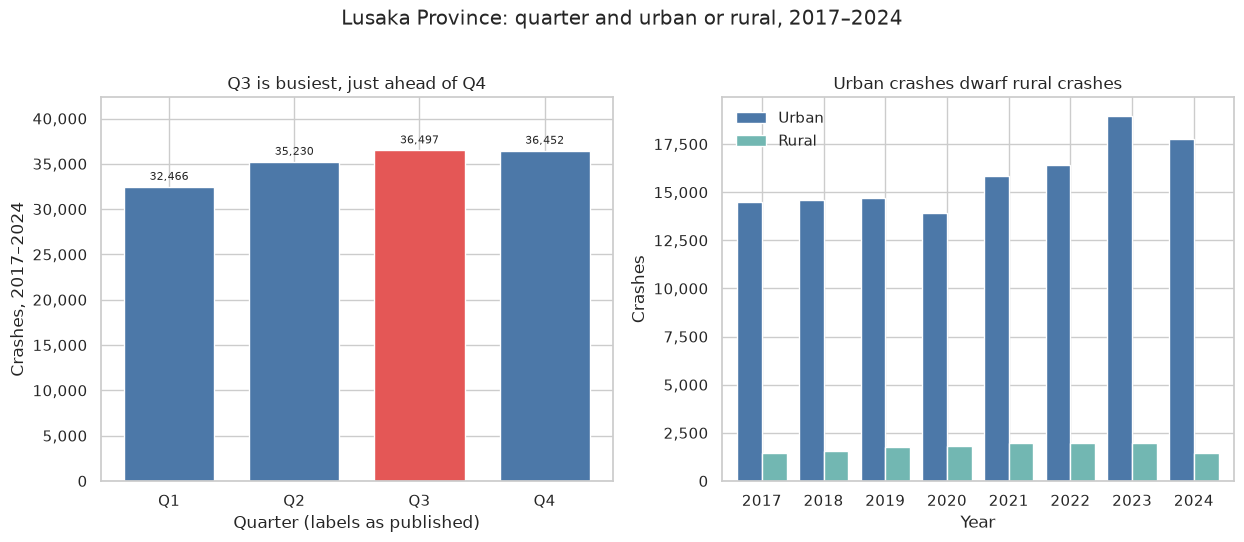

Saved images/02_lusaka_quarter_and_urban_rural.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 5.3))

quarter_colors = [RED if quarter == busiest_quarter else BLUE for quarter in by_quarter.index]
axes[0].bar(by_quarter.index, by_quarter.values, color=quarter_colors, width=0.72)
axes[0].set_title(f"{busiest_quarter} is busiest, just ahead of {second_quarter}")
axes[0].set_xlabel("Quarter (labels as published)")
axes[0].set_ylabel("Crashes, 2017–2024")
thousands(axes[0])
label_vertical(axes[0])

by_year_location.plot(kind="bar", ax=axes[1], color=[BLUE, TEAL], width=0.8)
axes[1].set_title("Urban crashes dwarf rural crashes")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Crashes")
axes[1].legend(title=None, frameon=False)
axes[1].tick_params(axis="x", rotation=0)
thousands(axes[1])

fig.suptitle("Lusaka Province: quarter and urban or rural, 2017–2024", y=1.02)
fig.tight_layout()
save_fig(fig, "02_lusaka_quarter_and_urban_rural.png")


## Question 3. What are the top 10 causes, and what changed?

Table x10 is also 2017–2024 for Lusaka, with 49 cause rows every year after the spelling fixes. Two of the labels are leftovers rather than a specific act: "Cause not traced" and "Other causes". Shares below use that year's cause records as the denominator. In most years those records add up to the crash total. In 2018 and 2021 they do not, so the shares are not forced onto the annual crash total.


In [10]:
lusaka_causes = causes.loc[causes["province"] == "LUSAKA"].copy()
cause_totals = lusaka_causes.groupby("cause")["count"].sum().sort_values(ascending=False)
top10 = cause_totals.head(10)
cause_by_year = lusaka_causes.pivot_table(index="year", columns="cause", values="count", aggfunc="sum").fillna(0)
cause_share = cause_by_year.div(cause_by_year.sum(axis=1), axis=0) * 100

top_table = pd.DataFrame({
    "records": top10.astype(int),
    "share_of_records_pct": (top10 / cause_totals.sum() * 100).round(1),
    "count_2017": cause_by_year.loc[2017, top10.index].astype(int),
    "count_2024": cause_by_year.loc[2024, top10.index].astype(int),
    "share_2017_pct": cause_share.loc[2017, top10.index].round(1),
    "share_2024_pct": cause_share.loc[2024, top10.index].round(1),
})
top_table["share_point_change"] = (
    cause_share.loc[2024, top10.index] - cause_share.loc[2017, top10.index]
).round(1)
top_table.index = [short_cause(label) for label in top_table.index]
display(top_table)

share_change = cause_share.loc[2024, top10.index] - cause_share.loc[2017, top10.index]
riser = share_change.idxmax()
faller = share_change.idxmin()
top3_share = cause_totals.head(3).sum() / cause_totals.sum() * 100

# Cause rows do not match the annual crash total in every Lusaka year.
crash_by_year = lusaka_annual.groupby("year")["count"].sum()
cause_vs_crash = pd.DataFrame({
    "cause_records": cause_by_year.sum(axis=1).astype(int),
    "annual_crashes": crash_by_year.reindex(cause_by_year.index).astype(int),
})
cause_vs_crash["gap"] = cause_vs_crash["cause_records"] - cause_vs_crash["annual_crashes"]
print("Lusaka cause records minus annual crashes (0 means the tables agree):")
display(cause_vs_crash)

rain = (
    lusaka_causes.loc[lusaka_causes["cause"].str.contains("Heavy rain", case=False), ["year", "count"]]
    .sort_values("year")
)
print("Reported 'heavy rain' crashes in Lusaka, which explains most of the 2021 gap:")
display(rain.set_index("year"))

print(
    f"Top cause: {short_cause(cause_totals.index[0])} "
    f"({int(cause_totals.iloc[0]):,}, {cause_totals.iloc[0] / cause_totals.sum() * 100:.1f}% of Lusaka cause records)."
)
print(f"The top three labels together are {top3_share:.1f}% of Lusaka cause records.")
print(
    f"Largest share increase, 2017 to 2024: {short_cause(riser)} "
    f"({cause_share.loc[2017, riser]:.1f}% to {cause_share.loc[2024, riser]:.1f}%, "
    f"{int(cause_by_year.loc[2017, riser]):,} to {int(cause_by_year.loc[2024, riser]):,})."
)
print(
    f"Largest share decrease: {short_cause(faller)} "
    f"({cause_share.loc[2017, faller]:.1f}% to {cause_share.loc[2024, faller]:.1f}%, "
    f"{int(cause_by_year.loc[2017, faller]):,} to {int(cause_by_year.loc[2024, faller]):,})."
)

residual = [
    label
    for label in top10.index
    if "not traced" in label.lower() or "other causes" in label.lower()
]
residual_text = " and ".join(
    f"{short_cause(label).lower()} ({int(cause_totals.loc[label]):,})" for label in residual
)

findings.append(
    f"The most common reported cause in Lusaka (2017–2024) was {short_cause(cause_totals.index[0]).lower()} "
    f"({int(cause_totals.iloc[0]):,} records, {cause_totals.iloc[0] / cause_totals.sum() * 100:.1f}% of cause records). "
    f"Next were {short_cause(cause_totals.index[1]).lower()} ({int(cause_totals.iloc[1]):,}) and "
    f"{short_cause(cause_totals.index[2]).lower()} ({int(cause_totals.iloc[2]):,}). "
    f"Together those three are {top3_share:.1f}% of Lusaka cause records. "
    f"The top 10 also includes labels that are not a specific act: {residual_text}."
)
findings.append(
    f"From 2017 to 2024, {short_cause(riser).lower()} rose from "
    f"{cause_share.loc[2017, riser]:.1f}% of Lusaka cause records to {cause_share.loc[2024, riser]:.1f}% "
    f"({int(cause_by_year.loc[2017, riser]):,} to {int(cause_by_year.loc[2024, riser]):,}). "
    f"{short_cause(faller)} fell from {cause_share.loc[2017, faller]:.1f}% to {cause_share.loc[2024, faller]:.1f}% "
    f"({int(cause_by_year.loc[2017, faller]):,} to {int(cause_by_year.loc[2024, faller]):,})."
)


,records,share_of_records_pct,count_2017,count_2024,share_2017_pct,share_2024_pct,share_point_change
Misjudging clearance distance,27615,19.5,3074,3961,19.2,20.7,1.4
Failing to keep to near side,25273,17.8,2651,2577,16.6,13.4,-3.2
Cutting,15158,10.7,2133,1465,13.4,7.6,-5.7
Reversing negligently,11928,8.4,1350,1505,8.4,7.8,-0.6
Excessive speed,10949,7.7,1100,1976,6.9,10.3,3.4
Failing to obey traffic sign/signal,8080,5.7,540,2328,3.4,12.1,8.8
Cause not traced,7982,5.6,1083,847,6.8,4.4,-2.4
Pedestrian crossing the road,7684,5.4,1071,1043,6.7,5.4,-1.3
Other causes,6338,4.5,903,445,5.7,2.3,-3.3
Overtaking Improperly,5357,3.8,599,1046,3.7,5.5,1.7


Lusaka cause records minus annual crashes (0 means the tables agree):


,cause_records,annual_crashes,gap
year,,,
2017,15977,15977,0
2018,16187,16176,11
2019,16435,16435,0
2020,15740,15740,0
2021,18801,17774,1027
2022,18393,18393,0
2023,20970,20970,0
2024,19180,19180,0


Reported 'heavy rain' crashes in Lusaka, which explains most of the 2021 gap:


,count
year,
2017,2
2018,9
2019,7
2020,9
2021,825
2022,12
2023,9
2024,1


Top cause: Misjudging clearance distance (27,615, 19.5% of Lusaka cause records).
The top three labels together are 48.0% of Lusaka cause records.
Largest share increase, 2017 to 2024: Failing to obey traffic sign/signal (3.4% to 12.1%, 540 to 2,328).
Largest share decrease: Cutting (13.4% to 7.6%, 2,133 to 1,465).


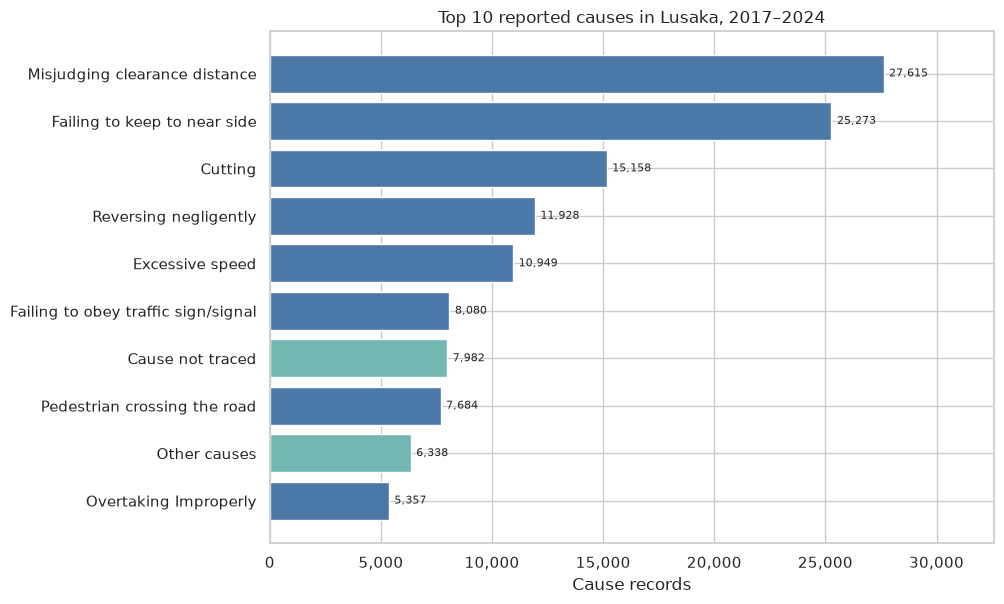

Saved images/03_lusaka_top_causes.png


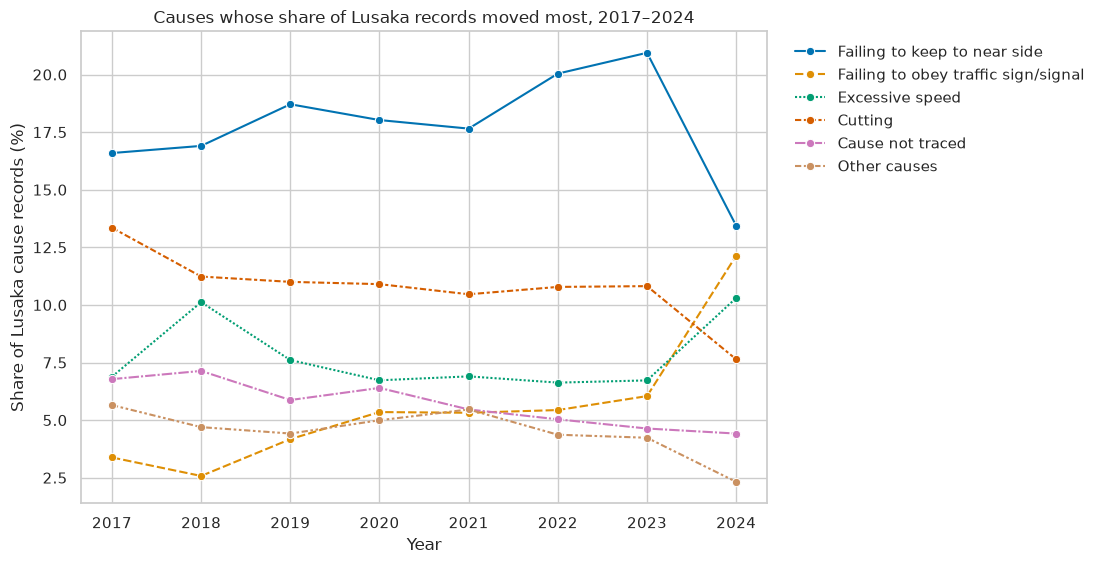

Saved images/03_lusaka_cause_trends.png


In [11]:
fig, ax = plt.subplots(figsize=(10.2, 6.2))
plot_top = top10.sort_values(ascending=True)
labels = [short_cause(label) for label in plot_top.index]
colors = [TEAL if "not traced" in label.lower() or label.lower().startswith("other causes") else BLUE for label in labels]
ax.barh(labels, plot_top.values, color=colors)
ax.set_title("Top 10 reported causes in Lusaka, 2017–2024")
ax.set_xlabel("Cause records")
thousands(ax, axis="x")
label_horizontal(ax)
fig.tight_layout()
save_fig(fig, "03_lusaka_top_causes.png")

# The six top-10 causes whose share moved the most. The chart follows the table.
movers = share_change.abs().sort_values(ascending=False).head(6).index
trend = cause_share[movers].rename(columns=short_cause).reset_index().melt(
    id_vars="year", var_name="cause", value_name="share"
)
# Draw the 2024 leader first so the legend matches the right-hand side of the chart.
legend_order = (
    cause_share.loc[2024, movers].sort_values(ascending=False).index.map(short_cause).tolist()
)

fig, ax = plt.subplots(figsize=(11.2, 5.8))
sns.lineplot(
    data=trend,
    x="year",
    y="share",
    hue="cause",
    hue_order=legend_order,
    style="cause",
    style_order=legend_order,
    marker="o",
    palette="colorblind",
    ax=ax,
)
ax.set_title("Causes whose share of Lusaka records moved most, 2017–2024")
ax.set_xlabel("Year")
ax.set_ylabel("Share of Lusaka cause records (%)")
ax.set_xticks(sorted(trend["year"].unique()))
ax.legend(title=None, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
save_fig(fig, "03_lusaka_cause_trends.png")


## Question 4. Which days and time slots are most dangerous?

"Most dangerous" here means the most reported crashes. The tables do not give severity by day or by hour, so a busy slot is not automatically the slot with the most deaths. Table x12 names its time column `day`. The values are ranges such as `1800-2000 hrs`, and the chart uses those ranges in clock order.


In [12]:
lusaka_days = days.loc[days["province"] == "LUSAKA"].copy()
lusaka_times = times.loc[times["province"] == "LUSAKA"].copy()
by_day = lusaka_days.groupby("day")["accidents"].sum().reindex(DAY_ORDER).astype(int)
by_time = lusaka_times.groupby("time_slot")["accidents"].sum().reindex(TIME_ORDER).astype(int)

busiest_day = by_day.idxmax()
second_day = by_day.sort_values(ascending=False).index[1]
quietest_day = by_day.idxmin()
day_gap = int(by_day.max() - by_day.sort_values(ascending=False).iloc[1])
busiest_time = by_time.idxmax()
quietest_time = by_time.idxmin()

display(by_day.to_frame("crashes"))
display(by_time.to_frame("crashes"))
print(
    f"{busiest_day} has the most crashes ({int(by_day.max()):,}), "
    f"{day_gap:,} ahead of {second_day} ({int(by_day.loc[second_day]):,}). "
    f"{quietest_day} has the fewest ({int(by_day.min()):,})."
)
print(
    f"The busiest time slot is {busiest_time} ({int(by_time.max()):,}). "
    f"The quietest is {quietest_time} ({int(by_time.min()):,})."
)

findings.append(
    f"{busiest_day} had the most Lusaka crashes in 2017–2024 ({int(by_day.max()):,}), "
    f"{day_gap:,} ahead of {second_day} ({int(by_day.loc[second_day]):,}). "
    f"{quietest_day} had the fewest ({int(by_day.min()):,}). "
    f"The busiest time slot was {busiest_time} ({int(by_time.max()):,} crashes) and the quietest was "
    f"{quietest_time} ({int(by_time.min()):,}). These tables do not split day or time by severity."
)


,crashes
day,
Monday,20352
Tuesday,19193
Wednesday,19076
Thursday,18947
Friday,22589
Saturday,22526
Sunday,17962


,crashes
time_slot,
07:00–09:00,16800
09:00–12:00,19144
12:00–14:30,18229
14:30–16:00,15233
16:00–18:00,19194
18:00–20:00,20069
20:00–23:59,18279
23:59–07:00,13697


Friday has the most crashes (22,589), 63 ahead of Saturday (22,526). Sunday has the fewest (17,962).
The busiest time slot is 18:00–20:00 (20,069). The quietest is 23:59–07:00 (13,697).


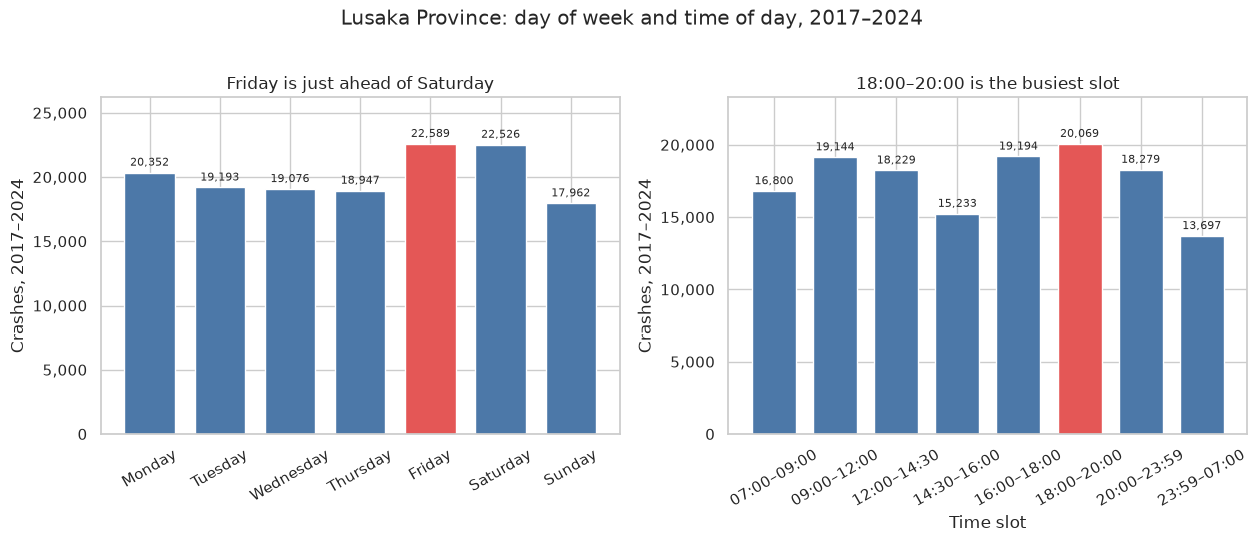

Saved images/04_lusaka_days_and_times.png


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.3))

day_colors = [RED if day == busiest_day else BLUE for day in by_day.index]
axes[0].bar(by_day.index, by_day.values, color=day_colors, width=0.72)
axes[0].set_title(f"{busiest_day} is just ahead of {second_day}")
axes[0].set_xlabel(None)
axes[0].set_ylabel("Crashes, 2017–2024")
axes[0].tick_params(axis="x", rotation=30)
thousands(axes[0])
label_vertical(axes[0])

time_colors = [RED if slot == busiest_time else BLUE for slot in by_time.index]
axes[1].bar(by_time.index, by_time.values, color=time_colors, width=0.72)
axes[1].set_title(f"{busiest_time} is the busiest slot")
axes[1].set_xlabel("Time slot")
axes[1].set_ylabel("Crashes, 2017–2024")
axes[1].tick_params(axis="x", rotation=30)
thousands(axes[1])
label_vertical(axes[1])

fig.suptitle("Lusaka Province: day of week and time of day, 2017–2024", y=1.02)
fig.tight_layout()
save_fig(fig, "04_lusaka_days_and_times.png")


## Question 5. Who is killed, and which vehicles are involved?

Table x6 counts **people killed**, not fatal crashes. One fatal crash can kill more than one person, and 2016 is not in this table. Table x9 counts **vehicles involved**. Several vehicles can be in one crash, so the vehicle total is larger than the crash total.

Other provinces means the nine provinces other than Lusaka. KKIA is left out of that comparison and reported on its own. It is an airport division, and only some years include it.


In [14]:
CLASS_LABELS = {
    "Pedestrian": "Pedestrian",
    "Ped/Cycle": "Pedal cyclist",
    "Ped/Cycle Passenger": "Pedal-cycle passenger",
    "Motor Cycle Driver": "Motorcycle driver",
    "Motor Cycle Passenger": "Motorcycle passenger",
    "Motor Vehicle Driver": "Motor-vehicle driver",
    "Motor Vehicle Passenger": "Motor-vehicle passenger",
}
VEHICLE_LABELS = {
    "Private M/Cars,Vans etc": "Private cars and vans",
    "Taxis/Contract Vehicles": "Taxis and contract vehicles",
    "Unknown M/V": "Unknown motor vehicle",
    "Motor Cycles": "Motorcycles",
    "Pedal Cycle": "Pedal cycles",
    "Goods Vehicles": "Goods vehicles",
}
PROVINCE_PRETTY = {
    "LUSAKA": "Lusaka",
    "COPPERBELT": "Copperbelt",
    "CENTRAL": "Central",
    "SOUTHERN": "Southern",
    "EASTERN": "Eastern",
    "NORTHERN": "Northern",
    "LUAPULA": "Luapula",
    "NORTH-WESTERN": "North-Western",
    "WESTERN": "Western",
    "MUCHINGA": "Muchinga",
    "KKIA": "KKIA (airport)",
}


def vehicle_label(name):
    return VEHICLE_LABELS.get(name, name)


lusaka_killed = killed.loc[killed["province"] == "LUSAKA"].copy()
other_killed = killed.loc[~killed["province"].isin(["LUSAKA", "KKIA"])].copy()
kkia_killed = int(killed.loc[killed["province"] == "KKIA", "number"].sum())

by_class = lusaka_killed.groupby("casualty_type")["number"].sum().sort_values(ascending=False).astype(int)
other_class = other_killed.groupby("casualty_type")["number"].sum().reindex(by_class.index).astype(int)
class_share = pd.DataFrame({
    "Lusaka": by_class / by_class.sum() * 100,
    "Other provinces": other_class / other_class.sum() * 100,
}).rename(index=CLASS_LABELS)

deaths_by_province = killed.groupby("province")["number"].sum().sort_values(ascending=False).astype(int)
lusaka_deaths = int(by_class.sum())
national_deaths = int(killed["number"].sum())
other_deaths = int(other_class.sum())

# Fatal crashes and people killed are different tables. Compare them only on shared years, 2017–2024.
fatal_crashes = (
    annual.loc[(annual["year"] >= 2017) & (annual["severity"] == "Fatal")]
    .groupby("province")["count"]
    .sum()
    .astype(int)
)
deaths_per_fatal = (deaths_by_province / fatal_crashes).dropna().sort_values(ascending=False)
lusaka_fatal_crashes = int(fatal_crashes["LUSAKA"])
other_fatal_crashes = int(fatal_crashes.drop(labels=["LUSAKA", "KKIA"]).sum())
lusaka_ratio = lusaka_deaths / lusaka_fatal_crashes
other_ratio = other_deaths / other_fatal_crashes
highest_ratio_province = deaths_per_fatal.drop(labels=["KKIA"]).idxmax()

print(f"People killed in Lusaka, 2017–2024: {lusaka_deaths:,}")
display(by_class.rename(index=CLASS_LABELS).to_frame("people_killed"))
display(class_share.round(1))
display(deaths_per_fatal.round(2).rename("deaths_per_fatal_crash").to_frame())
print(f"KKIA deaths, only in the years that division is reported: {kkia_killed:,}.")
print(
    f"Pedestrians are {by_class.iloc[0] / lusaka_deaths * 100:.1f}% of people killed in Lusaka "
    f"and {other_class.loc['Pedestrian'] / other_deaths * 100:.1f}% in the other provinces."
)
print(
    f"Lusaka is {lusaka_deaths / national_deaths * 100:.1f}% of people killed "
    f"({lusaka_deaths:,} of {national_deaths:,})."
)
print(
    f"Deaths per fatal crash, 2017–2024: {lusaka_ratio:.2f} in Lusaka "
    f"({lusaka_deaths:,} deaths / {lusaka_fatal_crashes:,} fatal crashes) and "
    f"{other_ratio:.2f} in the other provinces. "
    f"The highest provincial ratio is {PROVINCE_PRETTY[highest_ratio_province]} "
    f"at {deaths_per_fatal[highest_ratio_province]:.2f}."
)

findings.append(
    f"Of {lusaka_deaths:,} people killed in Lusaka from 2017 to 2024, "
    f"{int(by_class.iloc[0]):,} were pedestrians ({by_class.iloc[0] / lusaka_deaths * 100:.1f}%). "
    f"In the other nine provinces, pedestrians were {other_class.loc['Pedestrian'] / other_deaths * 100:.1f}% of "
    f"{other_deaths:,} deaths. Lusaka was {lusaka_deaths / national_deaths * 100:.1f}% of people killed nationally "
    f"({lusaka_deaths:,} of {national_deaths:,}), far below its {grand / national_total * 100:.1f}% share of all crashes. "
    f"KKIA adds {kkia_killed:,} deaths and is not included in the other-province share."
)
findings.append(
    f"Dividing people killed by fatal crashes for 2017–2024 gives {lusaka_ratio:.2f} deaths per fatal crash "
    f"in Lusaka ({lusaka_deaths:,} / {lusaka_fatal_crashes:,}) and {other_ratio:.2f} in the other provinces. "
    f"{PROVINCE_PRETTY[highest_ratio_province]} is highest at {deaths_per_fatal[highest_ratio_province]:.2f}. "
    f"These are two separate tables, so the ratio is a comparison rather than a figure from one record."
)


People killed in Lusaka, 2017–2024: 3,697


,people_killed
casualty_type,
Pedestrian,2414
Motor-vehicle passenger,649
Motor-vehicle driver,317
Pedal cyclist,219
Motorcycle driver,57
Pedal-cycle passenger,22
Motorcycle passenger,19


,Lusaka,Other provinces
casualty_type,,
Pedestrian,65.3,40.1
Motor-vehicle passenger,17.6,26.7
Motor-vehicle driver,8.6,11.3
Pedal cyclist,5.9,9.7
Motorcycle driver,1.5,5.8
Pedal-cycle passenger,0.6,1.9
Motorcycle passenger,0.5,4.5


,deaths_per_fatal_crash
province,
COPPERBELT,1.49
NORTHERN,1.27
CENTRAL,1.24
SOUTHERN,1.23
MUCHINGA,1.19
EASTERN,1.15
NORTH-WESTERN,1.15
WESTERN,1.14
LUAPULA,1.11


KKIA deaths, only in the years that division is reported: 13.
Pedestrians are 65.3% of people killed in Lusaka and 40.1% in the other provinces.
Lusaka is 23.3% of people killed (3,697 of 15,855).
Deaths per fatal crash, 2017–2024: 1.10 in Lusaka (3,697 deaths / 3,370 fatal crashes) and 1.25 in the other provinces. The highest provincial ratio is Copperbelt at 1.49.


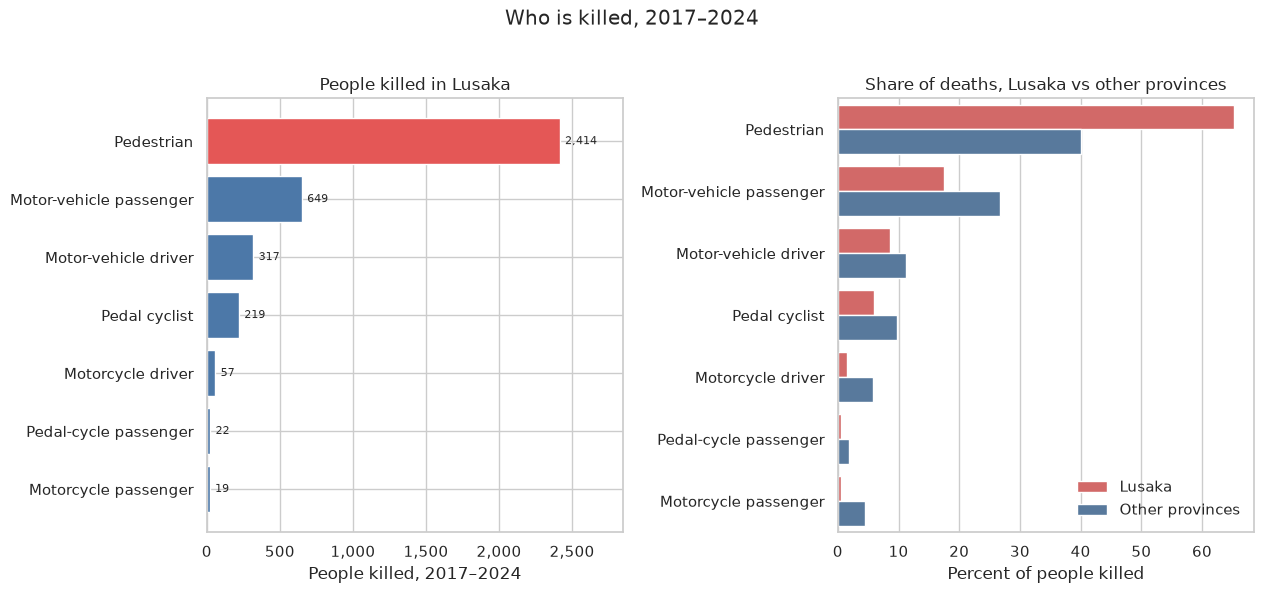

Saved images/05_who_is_killed.png


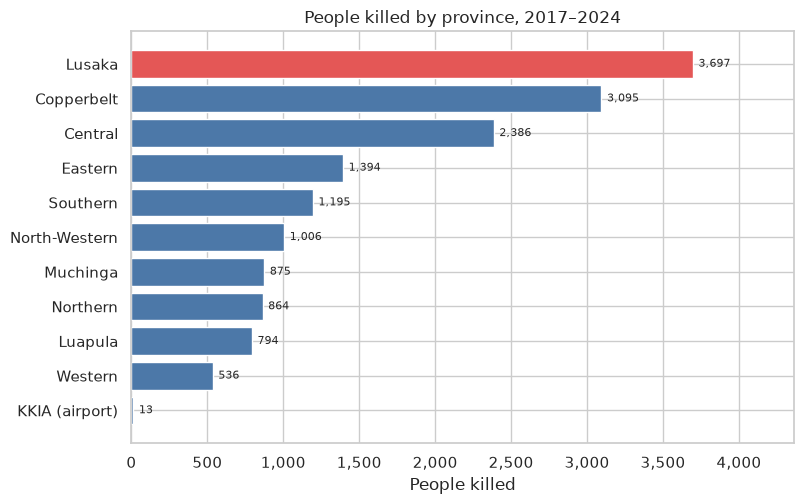

Saved images/05_deaths_by_province.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.8))

class_order = [CLASS_LABELS[name] for name in by_class.index]
class_colors = [RED if name == by_class.index[0] else BLUE for name in by_class.index]
axes[0].barh(class_order[::-1], by_class.values[::-1], color=class_colors[::-1])
axes[0].set_title("People killed in Lusaka")
axes[0].set_xlabel("People killed, 2017–2024")
thousands(axes[0], axis="x")
label_horizontal(axes[0])

share_long = class_share.reset_index(names="road_user").melt(
    id_vars="road_user", var_name="area", value_name="percent"
)
sns.barplot(
    data=share_long,
    y="road_user",
    x="percent",
    hue="area",
    order=class_order,
    hue_order=["Lusaka", "Other provinces"],
    palette=[RED, BLUE],
    ax=axes[1],
)
axes[1].set_title("Share of deaths, Lusaka vs other provinces")
axes[1].set_xlabel("Percent of people killed")
axes[1].set_ylabel(None)
axes[1].legend(title=None, frameon=False, loc="lower right")

fig.suptitle("Who is killed, 2017–2024", y=1.02)
fig.tight_layout()
save_fig(fig, "05_who_is_killed.png")

fig, ax = plt.subplots(figsize=(8.2, 5.2))
province_colors = [RED if province == "LUSAKA" else BLUE for province in deaths_by_province.index]
ax.barh(
    [PROVINCE_PRETTY[province] for province in deaths_by_province.index[::-1]],
    deaths_by_province.values[::-1],
    color=province_colors[::-1],
)
ax.set_title("People killed by province, 2017–2024")
ax.set_xlabel("People killed")
thousands(ax, axis="x")
label_horizontal(ax)
fig.tight_layout()
save_fig(fig, "05_deaths_by_province.png")


In [16]:
lusaka_vehicles = vehicles.loc[vehicles["province"] == "LUSAKA"].copy()
other_vehicles = vehicles.loc[~vehicles["province"].isin(["LUSAKA", "KKIA"])].copy()
by_vehicle = lusaka_vehicles.groupby("vehicle_type")["count"].sum().sort_values(ascending=False).astype(int)
other_vehicle = other_vehicles.groupby("vehicle_type")["count"].sum().astype(int)
vehicle_share = pd.DataFrame({
    "Lusaka": by_vehicle / by_vehicle.sum() * 100,
    "Other provinces": other_vehicle / other_vehicle.sum() * 100,
}).fillna(0)
# Keep types that are at least 2% of vehicles in Lusaka or in the other provinces.
keep = vehicle_share.index[(vehicle_share >= 2).any(axis=1)]
vehicle_share = vehicle_share.loc[keep].sort_values("Lusaka", ascending=False)

lusaka_vehicle_total = int(by_vehicle.sum())
private = "Private M/Cars,Vans etc"
taxis = "Taxis/Contract Vehicles"
print(f"Vehicles involved in Lusaka, 2017–2024: {lusaka_vehicle_total:,}")
display(by_vehicle.rename(index=vehicle_label).to_frame("vehicles_involved"))
display(vehicle_share.rename(index=vehicle_label).round(1))
print(
    f"Private cars and vans are {vehicle_share.loc[private, 'Lusaka']:.1f}% of vehicles involved in Lusaka "
    f"and {vehicle_share.loc[private, 'Other provinces']:.1f}% elsewhere."
)
print(
    f"Taxis and contract vehicles are {vehicle_share.loc[taxis, 'Lusaka']:.1f}% in Lusaka "
    f"and {vehicle_share.loc[taxis, 'Other provinces']:.1f}% in the other provinces."
)

findings.append(
    f"Private cars and vans were {int(by_vehicle.loc[private]):,} of {lusaka_vehicle_total:,} vehicles involved "
    f"in Lusaka crashes ({vehicle_share.loc[private, 'Lusaka']:.1f}%), against "
    f"{vehicle_share.loc[private, 'Other provinces']:.1f}% in the other provinces. "
    f"Taxis and contract vehicles were {vehicle_share.loc[taxis, 'Lusaka']:.1f}% in Lusaka and "
    f"{vehicle_share.loc[taxis, 'Other provinces']:.1f}% elsewhere. "
    f"Vehicle rows count vehicles involved, so the total is higher than the number of crashes, and 2016 is not in this table."
)


Vehicles involved in Lusaka, 2017–2024: 207,397


,vehicles_involved
vehicle_type,
Private cars and vans,145366
Goods vehicles,23664
Omni buses,21293
Unknown motor vehicle,7276
Motorcycles,4505
Pedal cycles,2361
Taxis and contract vehicles,2233
Carts,282
GRZ,278


,Lusaka,Other provinces
vehicle_type,,
Private cars and vans,70.1,46.6
Goods vehicles,11.4,17.2
Omni buses,10.3,9.9
Unknown motor vehicle,3.5,3.6
Motorcycles,2.2,6.6
Pedal cycles,1.1,5.5
Taxis and contract vehicles,1.1,8.4


Private cars and vans are 70.1% of vehicles involved in Lusaka and 46.6% elsewhere.
Taxis and contract vehicles are 1.1% in Lusaka and 8.4% in the other provinces.


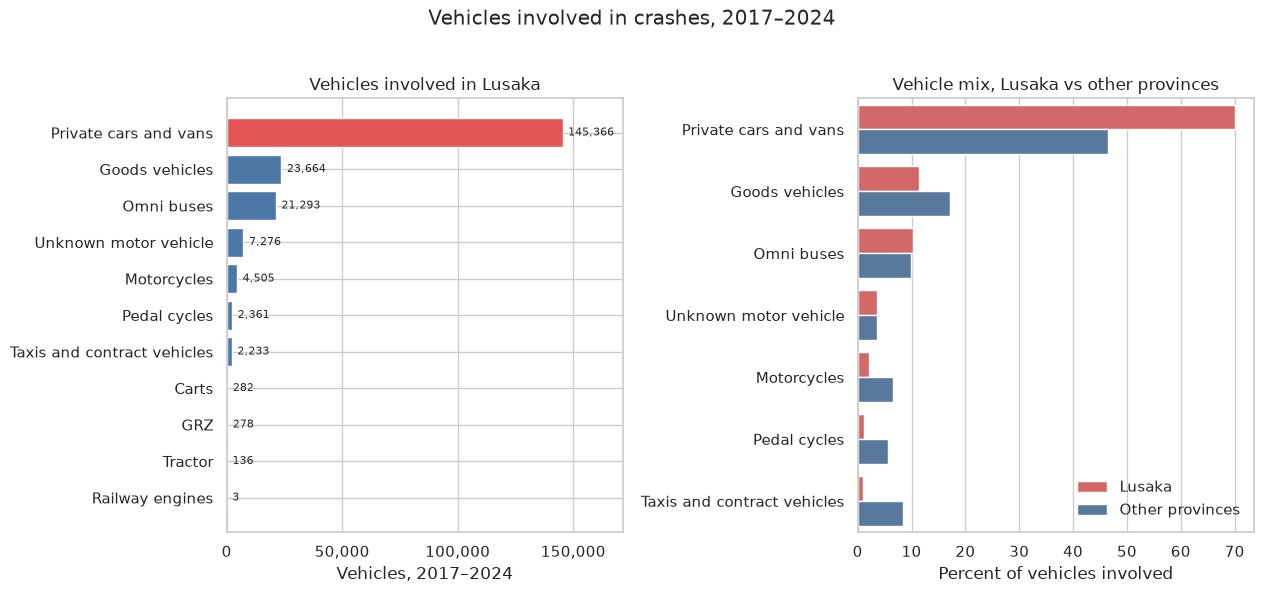

Saved images/05_vehicle_types.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.8))

vehicle_order = [vehicle_label(name) for name in by_vehicle.index]
vehicle_colors = [RED if name == private else BLUE for name in by_vehicle.index]
axes[0].barh(vehicle_order[::-1], by_vehicle.values[::-1], color=vehicle_colors[::-1])
axes[0].set_title("Vehicles involved in Lusaka")
axes[0].set_xlabel("Vehicles, 2017–2024")
thousands(axes[0], axis="x")
# The private-car bar is much longer than the others, so use fewer tick labels.
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=4))
label_horizontal(axes[0])

share_labels = [vehicle_label(name) for name in vehicle_share.index]
share_long = vehicle_share.rename(index=vehicle_label).reset_index(names="vehicle").melt(
    id_vars="vehicle", var_name="area", value_name="percent"
)
sns.barplot(
    data=share_long,
    y="vehicle",
    x="percent",
    hue="area",
    order=share_labels,
    hue_order=["Lusaka", "Other provinces"],
    palette=[RED, BLUE],
    ax=axes[1],
)
axes[1].set_title("Vehicle mix, Lusaka vs other provinces")
axes[1].set_xlabel("Percent of vehicles involved")
axes[1].set_ylabel(None)
axes[1].legend(title=None, frameon=False, loc="lower right")

fig.suptitle("Vehicles involved in crashes, 2017–2024", y=1.02)
fig.tight_layout()
save_fig(fig, "05_vehicle_types.png")


## Question 6. How many crashes does Zambia record per 100,000 people?

This is the national figure, not the Lusaka figure. Population is not in the crash tables. `published_derived_indicators.csv` is the series the dataset authors released with the crash tables. The notebook adds up crashes from table x1, divides by that population, and multiplies by 100,000.

`rate = accidents / human_population × 100,000`

The result is saved to `outputs/derived_indicators.csv`. Vehicle population is copied across so the file has the same columns as the published series. It is not used in the rate.


In [18]:
published = pd.read_csv(DATA / "published_derived_indicators.csv").rename(
    columns={"accidents": "accidents_published", "rate_per_100k": "rate_per_100k_published"}
)
rates = (
    annual.groupby("year", as_index=False)["count"]
    .sum()
    .rename(columns={"count": "accidents"})
    .merge(
        published[
            [
                "year",
                "human_population",
                "vehicle_population",
                "accidents_published",
                "rate_per_100k_published",
            ]
        ],
        on="year",
        how="outer",
    )
)
if rates[["accidents", "human_population"]].isna().any().any():
    raise ValueError("The population series does not cover the same years as table x1.")

rates["rate_per_100k"] = rates["accidents"] / rates["human_population"] * 100_000
counts_match = bool((rates["accidents"] == rates["accidents_published"]).all())
rates_match = bool((rates["rate_per_100k"] - rates["rate_per_100k_published"]).abs().max() < 1e-6)
print(f"Accident totals from x1 match the published series: {counts_match}")
print(f"Recomputed rates match the published series: {rates_match}")
if not (counts_match and rates_match):
    raise ValueError("The recomputed national rate does not match the published series.")

out = rates[["year", "accidents", "human_population", "vehicle_population", "rate_per_100k"]].sort_values("year")
out.to_csv(OUTPUTS / "derived_indicators.csv", index=False)
display(out.assign(rate_per_100k=out["rate_per_100k"].round(2)))

high_row = out.loc[out["rate_per_100k"].idxmax()]
low_row = out.loc[out["rate_per_100k"].idxmin()]
change = (low_row["rate_per_100k"] - high_row["rate_per_100k"]) / high_row["rate_per_100k"] * 100
print(f"Saved outputs/derived_indicators.csv ({len(out)} years).")
print(
    f"Highest rate: {int(high_row['year'])} at {high_row['rate_per_100k']:.2f} per 100,000 people. "
    f"Lowest: {int(low_row['year'])} at {low_row['rate_per_100k']:.2f} "
    f"({change:.1f}% versus the highest year)."
)

findings.append(
    f"Nationally, reported crashes per 100,000 people were highest in {int(high_row['year'])} "
    f"({high_row['rate_per_100k']:.2f}) and lowest in {int(low_row['year'])} "
    f"({low_row['rate_per_100k']:.2f}), {abs(change):.1f}% lower. "
    f"The {int(out.iloc[-1]['year'])} rate was {out.iloc[-1]['rate_per_100k']:.2f}. "
    f"Crash totals come from table x1. Population is the series published with the dataset, "
    f"and the recomputed rates match that published file."
)


Accident totals from x1 match the published series: True
Recomputed rates match the published series: True


,year,accidents,human_population,vehicle_population,rate_per_100k
0,2016,32350,16914423,696474,191.26
1,2017,30163,17441320,737671,172.94
2,2018,30652,17973569,782136,170.54
3,2019,30648,18513839,822882,165.54
4,2020,28484,19059395,853909,149.45
5,2021,32372,19604025,899186,165.13
6,2022,33682,20152938,960237,167.13
7,2023,36755,20723965,1046703,177.36
8,2024,35731,21314956,1121703,167.63


Saved outputs/derived_indicators.csv (9 years).
Highest rate: 2016 at 191.26 per 100,000 people. Lowest: 2020 at 149.45 (-21.9% versus the highest year).


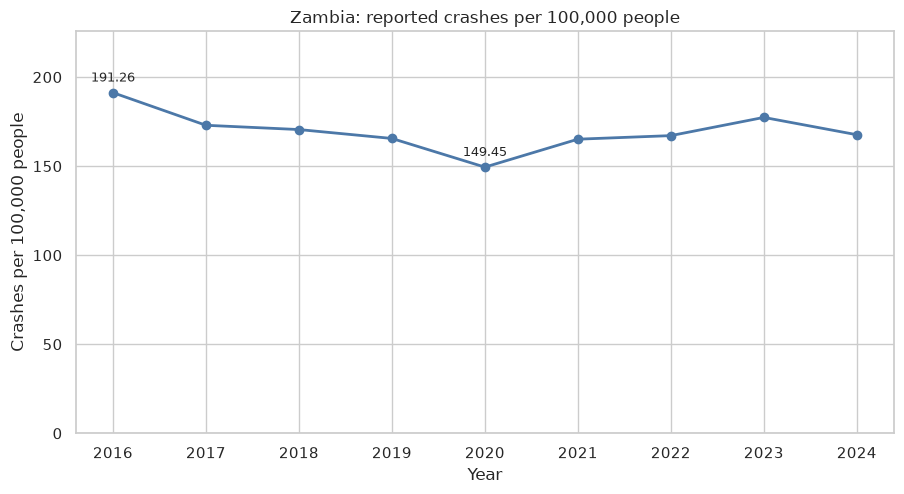

Saved images/06_national_crashes_per_100k.png


In [19]:
fig, ax = plt.subplots(figsize=(9.2, 5.1))
ax.plot(out["year"], out["rate_per_100k"], marker="o", color=BLUE, linewidth=2)
for _, row in out.loc[out["year"].isin([int(high_row["year"]), int(low_row["year"])])].iterrows():
    ax.annotate(
        f"{row['rate_per_100k']:.2f}",
        (row["year"], row["rate_per_100k"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
    )
ax.set_title("Zambia: reported crashes per 100,000 people")
ax.set_xlabel("Year")
ax.set_ylabel("Crashes per 100,000 people")
ax.set_xticks(out["year"].tolist())
ax.set_ylim(0, out["rate_per_100k"].max() * 1.18)
fig.tight_layout()
save_fig(fig, "06_national_crashes_per_100k.png")


## What the run found

The sentences below are built from the tables in this notebook. They are the numbers to quote.


In [20]:
for number, sentence in enumerate(findings, start=1):
    print(f"{number}. {sentence}")
    print()


1. From 2016 to 2024, Lusaka Province recorded 157,962 reported crashes. 120,791 (76.5%) were damage only, 26,082 (16.5%) slight, 7,267 (4.6%) serious, and 3,822 (2.4%) fatal.

2. The busiest year was 2023 with 20,970 crashes, and the quietest was 2020 with 15,740. Fatal crashes peaked in 2021 (488), which is not the year with the most crashes.

3. Lusaka accounted for 54.3% of crashes reported in Zambia (157,962 of 290,837) but 25.9% of fatal crashes (3,822 of 14,743). The extra volume is mostly damage-only crashes.

4. In 2017–2024, Q3 was Lusaka's busiest quarter with 36,497 crashes, only 45 ahead of Q4 (36,452). The leading quarter changes by year: 2017 Q4, 2018 Q3, 2019 Q3, 2020 Q4, 2021 Q4, 2022 Q3, 2023 Q3, 2024 Q2.

5. Over those same years, 126,685 Lusaka crashes were urban (90.1%) and 13,960 were rural (9.9%). The urban share stays near 90% in every year. Table x2 has no 2016 rows.

6. The most common reported cause in Lusaka (2017–2024) was misjudging clearance distance (27,

## Limits of these answers

- A row is a published total. The notebook cannot say which junction, which age, or which single crash sits behind a number.
- Table x1 runs from 2016 to 2024. The quarter, cause, day, time, death, and vehicle tables start in 2017. Those answers do not include 2016, and they say so.
- KKIA appears only in some years. It is not folded into Lusaka Province.
- After the empty pivot columns are removed, the count fields have no blanks. About a quarter of cause rows are stored as zero. Those zeros stay. They are not filled in.
- Lusaka's quarterly totals match the annual totals. One other province-year does not: Eastern Province in 2018. That gap is left as it is.
- Lusaka cause records match the annual crash total in most years, but not in 2018 or 2021. The 2021 gap is mostly a heavy-rain count that jumps far above the years around it. The top 10 does not depend on that row, and the notebook does not delete it.
- People killed and fatal crashes come from different tables. The deaths-per-fatal-crash comparison is only a way to put those two totals next to each other.
- Population is the authors' published series, not a new census extract. A change in the crash rate can be a change in crashes, in population, or in how completely crashes were reported.
